# 05 — Karar Ağacı ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Karar ağacı, özellik uzayını ardışık "eşik sorusu" ile dikdörtgen bölgelere
ayırır; her yaprak bir tahmin değeri ya da sınıf taşır. En yorumlanabilir modeldir:
kökten yaprağa izlenen yol doğrudan okunabilir bir kuraldır ("yükseklik 1250 m'den
alçak ve yerleşime uzaklık 2 km'den azsa…"). Ölçekleme gerektirmez, ancak derinleştikçe
aşırı öğrenmeye son derece yatkındır. Bu nedenle ağaç **max_depth = 20** ve yaprak
başına en az 5 örnek koşuluyla budanmıştır.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
reg_model = DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1460
   MSE: 0.1148
  RMSE: 0.3388
    R2: 0.5407
   AUC: 0.9028


In [3]:
o.reg_grafikleri(yr_te, y_pred, "Karar Ağacı", "karar_agaci")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\karar_agaci_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                             class_weight='balanced', random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8736
   BalancedAcc: 0.8734
      F1_macro: 0.8735
   F1_weighted: 0.8736

              precision    recall  f1-score   support

  Yangın Yok      0.867     0.888     0.877       653
      Yangın      0.881     0.859     0.870       629

    accuracy                          0.874      1282
   macro avg      0.874     0.873     0.874      1282
weighted avg      0.874     0.874     0.874      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1460 |   0.4998 |    0.3931 | -0.2470 (iyi)
     MSE |   0.1148 |   0.2499 |    0.1978 | -0.0830 (iyi)
    RMSE |   0.3388 |   0.4999 |    0.4447 | -0.1059 (iyi)
      R2 |   0.5407 |  -0.0000 |    0.2086 | +0.3321 (iyi)
     AUC |   0.9028 |   0.5000 |    0.6982 | +0.2046 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8736 |   0.5094 |    0.6934 | +0.1802
     BalancedAcc |  0.8734 |   0.5000 |    0.6982 | +0.1752
        F1_macro |  0.8735 |   0.3375 |    0.6748 | +0.1987
     F1_weighted |  0.8736 |   0.3438 |    0.6733 | +0.2002
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "Karar Ağacı", "karar_agaci")

Karar Ağacı — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   580     73
      Yangın |    89    540


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\karar_agaci_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### Ağaç Yapısı, Özellik Önemleri ve Derinliğin Etkisi

Budanmamış bir ağaç eğitim verisini neredeyse ezberler; test performansı ise bir
noktadan sonra düşer. Aşağıda önce sınıflandırma ağacının özellik önemleri ve ilk üç
seviyesi (okunabilirlik için) gösterilir, ardından derinliğin performansa etkisi
ölçülür; aşırı öğrenmenin en somut gösterimi budur.

In [7]:
o.ozellik_onem_grafigi(clf.feature_importances_, "Karar Ağacı", "karar_agaci")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\karar_agaci_onem.png'

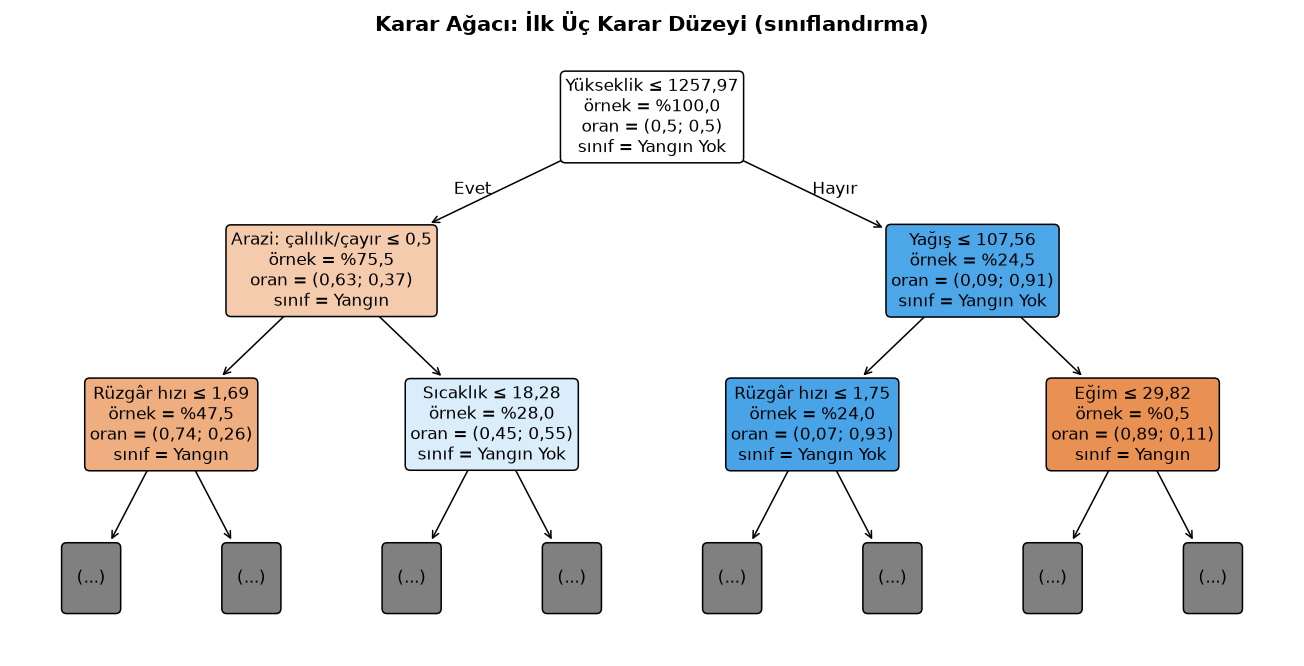

Kök düğüm kuralı: {'ozellik': 'Yukseklik', 'esik': 1257.9739990234375}
Budanmış ağaç: derinlik 16, yaprak 270
Budanmamış ağaç: {'derinlik': 19, 'yaprak': 427, 'test_F1': 0.8710745010559421, 'egitim_F1': 1.0}


In [8]:
kucuk = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42).fit(X_tr, yc_tr)
# Kitapta okunabilmesi için ilk üç karar düzeyi (kök + iki alt düzey) çizilir; daha
# alttaki düğümler "(...)" ile kısaltılır. Ondalıklar iki basamakla gösterilir.
fig, ax = plt.subplots(figsize=(12, 6.2))
yazilar = plot_tree(kucuk, feature_names=[o.OKUNUR[c] for c in o.OZELLIKLER], class_names=list(kucuk.classes_),
                    filled=True, rounded=True, fontsize=11, ax=ax, impurity=False, proportion=True,
                    max_depth=2, precision=2)
# Düğüm yazıları Türkçeleştirilir: örnek payı, sınıf oranları, ondalık virgül.
import re as _re
for y in yazilar:
    t = y.get_text()
    t = t.replace("samples = ", "örnek = %").replace("value = ", "oran = ").replace("class = ", "sınıf = ")
    t = t.replace(" <= ", " ≤ ").replace("≤ -", "≤ −")
    t = _re.sub(r"(\d)\.(\d)", r"\1,\2", t)
    t = _re.sub(r"örnek = %([\d,]+)%", r"örnek = %\1", t)
    t = t.replace("[", "(").replace("]", ")").replace(", ", "; ")
    y.set_text(t)
import matplotlib.text as _mt
for metin in ax.findobj(_mt.Text):
    if metin.get_text().strip() in ("True", "False"):
        metin.set_text("Evet" if metin.get_text().strip() == "True" else "Hayır")
ax.set_title("Karar Ağacı: İlk Üç Karar Düzeyi (sınıflandırma)", fontsize=14)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "dt_agac.png"), bbox_inches="tight")
plt.show()
kok = kucuk.tree_
kok_kural = {"ozellik": o.OZELLIKLER[kok.feature[0]], "esik": float(kok.threshold[0])}
print("Kök düğüm kuralı:", kok_kural)
derin = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_tr, yc_tr)
budanmamis = {"derinlik": int(derin.get_depth()), "yaprak": int(derin.get_n_leaves()),
              "test_F1": o.cls_metrikleri(yc_te, derin.predict(X_te))["F1_macro"],
              "egitim_F1": o.cls_metrikleri(yc_tr, derin.predict(X_tr))["F1_macro"]}
print(f"Budanmış ağaç: derinlik {clf.get_depth()}, yaprak {clf.get_n_leaves()}")
print("Budanmamış ağaç:", budanmamis)

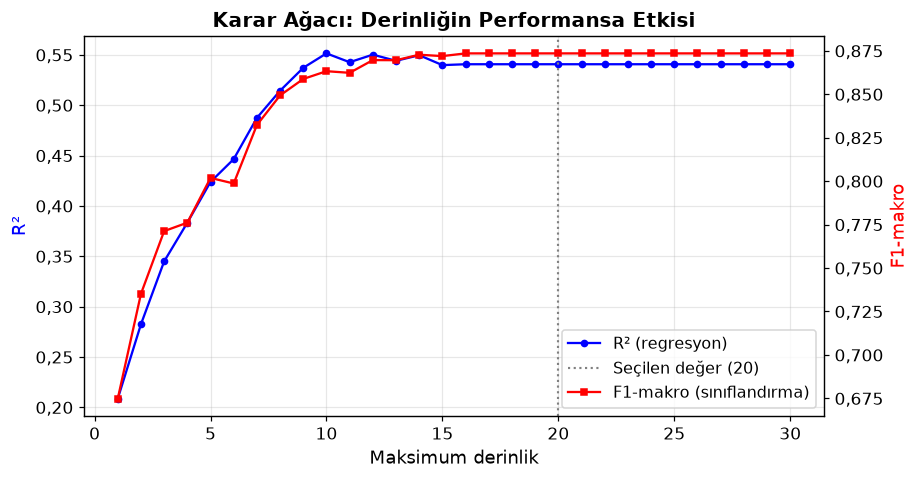

Tarama: [(1, 0.2086, 0.6748), (2, 0.2825, 0.7352), (3, 0.3449, 0.7712), (4, 0.3833, 0.7761), (5, 0.4238, 0.8018), (6, 0.4465, 0.7986), (7, 0.4874, 0.8323), (8, 0.5144, 0.8493), (9, 0.5371, 0.8588), (10, 0.5514, 0.8633), (11, 0.5427, 0.8623), (12, 0.5502, 0.8696), (13, 0.5441, 0.8696), (14, 0.5496, 0.8727), (15, 0.5398, 0.872), (16, 0.5407, 0.8735), (17, 0.5407, 0.8735), (18, 0.5407, 0.8735), (19, 0.5407, 0.8735), (20, 0.5407, 0.8735), (21, 0.5407, 0.8735), (22, 0.5407, 0.8735), (23, 0.5407, 0.8735), (24, 0.5407, 0.8735), (25, 0.5407, 0.8735), (26, 0.5407, 0.8735), (27, 0.5407, 0.8735), (28, 0.5407, 0.8735), (29, 0.5407, 0.8735), (30, 0.5407, 0.8735)]
En yüksek R²: 0.5514 (10) · en yüksek F1-makro: 0.8735 (16)


In [9]:
degerler = list(range(1, 31))
r2_list, f1_list = [], []
for dd in degerler:
    r = DecisionTreeRegressor(max_depth=dd, min_samples_leaf=5, random_state=42).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = DecisionTreeClassifier(max_depth=dd, min_samples_leaf=5, class_weight='balanced',
                               random_state=42).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(20, color="gray", ls=":", lw=1.4, label="Seçilen değer (20)")
ax1.set_xlabel("Maksimum derinlik")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("Karar Ağacı: Derinliğin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "dt_derinlik_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [10]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42).fit(Xa, yra).predict(Xb)
    c_tahmin = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.2203 · F1-makro 0.6891
  kat 2: eğitim  4170 · sınama   958 · R² -0.3060 · F1-makro 0.6164


  kat 3: eğitim  4114 · sınama  1014 · R² +0.2690 · F1-makro 0.7917


  kat 4: eğitim  4055 · sınama  1073 · R² +0.2216 · F1-makro 0.7752
  kat 5: eğitim  4150 · sınama   978 · R² +0.2367 · F1-makro 0.7800
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.0402 ± 0.2496
  F1-makro: 0.7305 ± 0.0677


In [11]:
o.sonuc_kaydet("karar_agaci", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp], "agac_derinligi": int(clf.get_depth()), "yaprak_sayisi": int(clf.get_n_leaves()), "max_depth_ayar": 20, "kok_kural": kok_kural, "budanmamis": budanmamis})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\karar_agaci.json


{'algoritma': 'karar_agaci',
 'regresyon': {'MAE': 0.146010388034569,
  'MSE': 0.11479291254983534,
  'RMSE': 0.3388110277866341,
  'R2': 0.5406673691302328,
  'AUC': 0.9028137226497734},
 'siniflandirma': {'Accuracy': 0.8736349453978159,
  'BalancedAcc': 0.8733569169565927,
  'F1_macro': 0.873511806880221,
  'F1_weighted': 0.8735856899907779},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.22028787562065233,
    -0.3060331626555639,
    0.26898114353156943,
    0.22160396334814236,
    0.236730416599789],
   'F1_macro': [0.6890653282869836,
    0.6164432029795158,
    0.7916666666666667,
    0.7751703439395639,
    0.779993692841375],
   'R2_ort': 0.04019889704065691,
   'R2_std': 0.24964124277236938,
   'F1_ort': 0.730467846942821,
   'F1_std': 0.06769373112380253},
  'duyarlilik': {'degerler': [1.0,
    2.0,
    3.0,
    4.0,
    5.0,
    6.0,
    7.0,
    8.0,
    9.0,
    10.0,
    11.0,
    12.0,
    13.0,
    14.0,
    15.0,
    16.0,
    17.0,
    18.0,
    19.0,
    20